# Model Evaluation Metrics

This notebook reads all `test_predictions.csv` files from the `models/` directory and calculates:
- Accuracy
- F1 Macro
- F1 Weighted
- Precision (Weighted)
- Recall (Weighted)
- AUC (One-vs-Rest)

In [133]:
# Import required libraries
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score
)
import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [134]:
# Find all test_predictions.csv files in models directory
models_dir = Path('../models')
prediction_files = list(models_dir.glob('*/test_predictions.csv'))

print(f"Found {len(prediction_files)} model prediction files:")
for file in prediction_files:
    print(f"  - {file.parent.name}")

Found 8 model prediction files:
  - Qwen_Qwen2.5_0.5B
  - Qwen_Qwen2.5_1.5B
  - Qwen_Qwen2.5_3B
  - Qwen_Qwen2.5_7B
  - Qwen_Qwen3_0.6B
  - Qwen_Qwen3_1.7B
  - Qwen_Qwen3_4B
  - Qwen_Qwen3_8B


In [135]:
# Function to calculate all metrics
def calculate_metrics(df):
    """
    Calculate all evaluation metrics from test predictions DataFrame
    
    Args:
        df: DataFrame with columns [true_label, predicted_label, prob_no, prob_intrinsic, prob_extrinsic]
    
    Returns:
        dict: Dictionary containing all metrics
    """
    # Get true and predicted labels
    y_true = df['true_label'].values
    y_pred = df['predicted_label'].values
    
    # Get probability columns
    y_probs = df[['prob_no', 'prob_intrinsic', 'prob_extrinsic']].values
    
    # Convert labels to numeric for AUC calculation
    label_map = {'no': 0, 'intrinsic': 1, 'extrinsic': 2}
    y_true_numeric = np.array([label_map[label] for label in y_true])
    
    # Calculate metrics
    metrics = {
        'Accuracy': accuracy_score(y_true, y_pred),
        'F1 Macro': f1_score(y_true, y_pred, average='macro'),
        'F1 Weighted': f1_score(y_true, y_pred, average='weighted'),
        'Precision': precision_score(y_true, y_pred, average='weighted', zero_division=0),
        'Recall': recall_score(y_true, y_pred, average='weighted', zero_division=0),
        'AUC': roc_auc_score(y_true_numeric, y_probs, multi_class='ovr', average='weighted')
    }
    
    return metrics

print("Metric calculation function defined!")

Metric calculation function defined!


In [136]:
# Calculate metrics for all models
results = []

for pred_file in prediction_files:
    model_name = pred_file.parent.name
    
    try:
        # Read predictions
        df = pd.read_csv(pred_file)
        
        # Calculate metrics
        metrics = calculate_metrics(df)
        metrics['Model'] = model_name
        
        results.append(metrics)
        print(f"✓ Processed {model_name}")
        
    except Exception as e:
        print(f"✗ Error processing {model_name}: {e}")

print(f"\nSuccessfully processed {len(results)} models")

✓ Processed Qwen_Qwen2.5_0.5B
✓ Processed Qwen_Qwen2.5_1.5B
✓ Processed Qwen_Qwen2.5_3B
✓ Processed Qwen_Qwen2.5_7B
✓ Processed Qwen_Qwen3_0.6B
✓ Processed Qwen_Qwen3_1.7B
✓ Processed Qwen_Qwen3_4B
✓ Processed Qwen_Qwen3_8B

Successfully processed 8 models


In [137]:
# Create results DataFrame
results_df = pd.DataFrame(results)

# Reorder columns
results_df = results_df[['Model', 'Accuracy', 'F1 Macro', 'F1 Weighted', 'Precision', 'Recall', 'AUC']]

results_df['Model'] = results_df['Model'].str.split('_').str[1:].str.join('-')

# Sort by F1 Macro (descending)
results_df = results_df.sort_values('F1 Macro', ascending=False).reset_index(drop=True)

# Format to 4 decimal places
for col in ['Accuracy', 'F1 Macro', 'F1 Weighted', 'Precision', 'Recall', 'AUC']:
    results_df[col] = results_df[col].apply(lambda x: f"{x:.4f}")

print("\n" + "="*100)
print("MODEL EVALUATION RESULTS")
print("="*100)
print(results_df.to_string(index=False))
print("="*100)


MODEL EVALUATION RESULTS
       Model Accuracy F1 Macro F1 Weighted Precision Recall    AUC
    Qwen3-8B   0.8455   0.8454      0.8457    0.8462 0.8455 0.9377
  Qwen2.5-7B   0.8390   0.8390      0.8392    0.8406 0.8390 0.8570
    Qwen3-4B   0.8385   0.8383      0.8387    0.8393 0.8385 0.9410
  Qwen3-1.7B   0.7960   0.7971      0.7969    0.8010 0.7960 0.9268
  Qwen2.5-3B   0.7825   0.7841      0.7836    0.7856 0.7825 0.9046
Qwen2.5-1.5B   0.7750   0.7751      0.7746    0.7744 0.7750 0.9066
  Qwen3-0.6B   0.7535   0.7529      0.7526    0.7526 0.7535 0.8895
Qwen2.5-0.5B   0.6340   0.6368      0.6363    0.6415 0.6340 0.8005


In [138]:
# Save results to CSV
output_file = '../results/model_comparison.csv'
results_df.to_csv(output_file, index=False)
print(f"\n✓ Results saved to {output_file}")


✓ Results saved to ../results/model_comparison.csv


In [139]:
# Generate Markdown table for README
print("\n" + "="*100)
print("MARKDOWN TABLE FOR README.md")
print("="*100)
print("\n| Models | Accuracy | F1 Macro | F1 Weighted | Precision | Recall | AUC |")
print("|--------|----------|----------|-------------|-----------|--------|-----|")

for _, row in results_df.iterrows():
    print(f"| {row['Model']} | {row['Accuracy']} | {row['F1 Macro']} | {row['F1 Weighted']} | {row['Precision']} | {row['Recall']} | {row['AUC']} |")

print("\n" + "="*100)


MARKDOWN TABLE FOR README.md

| Models | Accuracy | F1 Macro | F1 Weighted | Precision | Recall | AUC |
|--------|----------|----------|-------------|-----------|--------|-----|
| Qwen3-8B | 0.8455 | 0.8454 | 0.8457 | 0.8462 | 0.8455 | 0.9377 |
| Qwen2.5-7B | 0.8390 | 0.8390 | 0.8392 | 0.8406 | 0.8390 | 0.8570 |
| Qwen3-4B | 0.8385 | 0.8383 | 0.8387 | 0.8393 | 0.8385 | 0.9410 |
| Qwen3-1.7B | 0.7960 | 0.7971 | 0.7969 | 0.8010 | 0.7960 | 0.9268 |
| Qwen2.5-3B | 0.7825 | 0.7841 | 0.7836 | 0.7856 | 0.7825 | 0.9046 |
| Qwen2.5-1.5B | 0.7750 | 0.7751 | 0.7746 | 0.7744 | 0.7750 | 0.9066 |
| Qwen3-0.6B | 0.7535 | 0.7529 | 0.7526 | 0.7526 | 0.7535 | 0.8895 |
| Qwen2.5-0.5B | 0.6340 | 0.6368 | 0.6363 | 0.6415 | 0.6340 | 0.8005 |




✓ Visualization saved to ../results/model_comparison.png


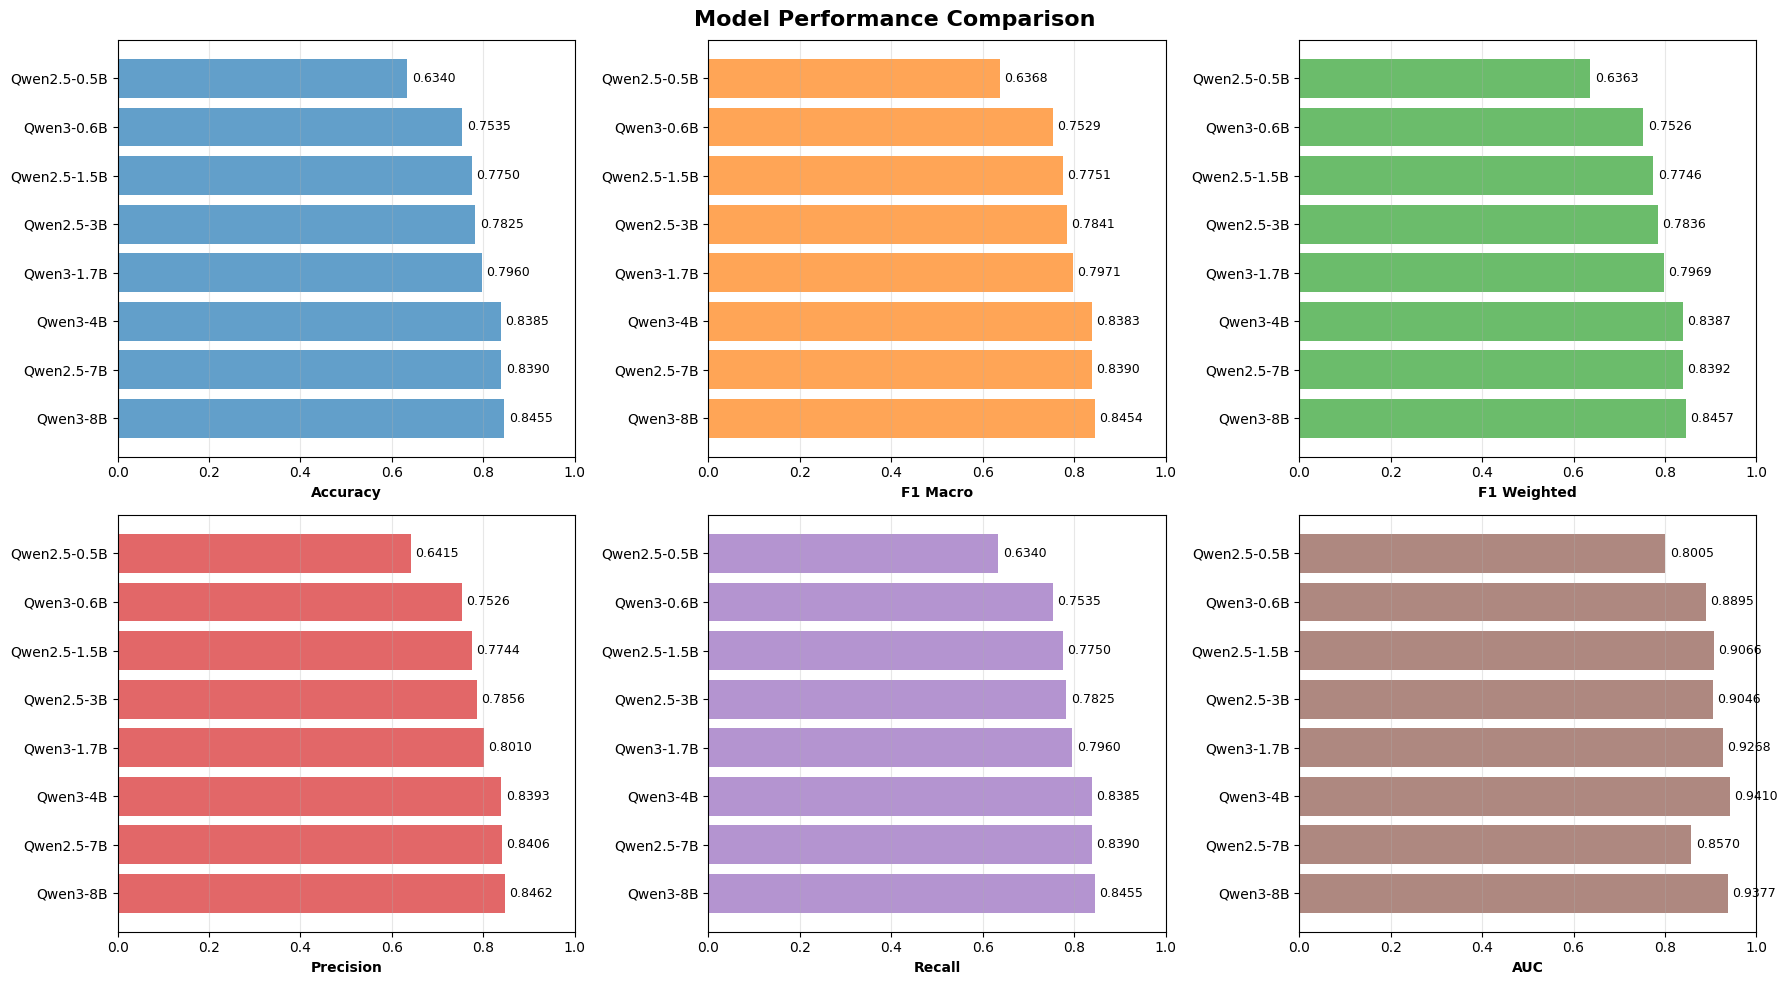

In [140]:
# Visualize comparison (optional)
import matplotlib.pyplot as plt

# Convert back to numeric for plotting
plot_df = results_df.copy()
for col in ['Accuracy', 'F1 Macro', 'F1 Weighted', 'Precision', 'Recall', 'AUC']:
    plot_df[col] = plot_df[col].astype(float)

# Create bar plot
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Model Performance Comparison', fontsize=16, fontweight='bold')

metrics = ['Accuracy', 'F1 Macro', 'F1 Weighted', 'Precision', 'Recall', 'AUC']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']

for idx, (ax, metric, color) in enumerate(zip(axes.flatten(), metrics, colors)):
    ax.barh(plot_df['Model'], plot_df[metric], color=color, alpha=0.7)
    ax.set_xlabel(metric, fontweight='bold')
    ax.set_xlim(0, 1)
    ax.grid(axis='x', alpha=0.3)
    
    # Add value labels
    for i, v in enumerate(plot_df[metric]):
        ax.text(v + 0.01, i, f'{v:.4f}', va='center', fontsize=9)

plt.tight_layout()
plt.savefig('../results/model_comparison.png', dpi=300, bbox_inches='tight')
print("\n✓ Visualization saved to ../results/model_comparison.png")
plt.show()


✓ Line chart saved to ../results/f1_vs_model_size.png


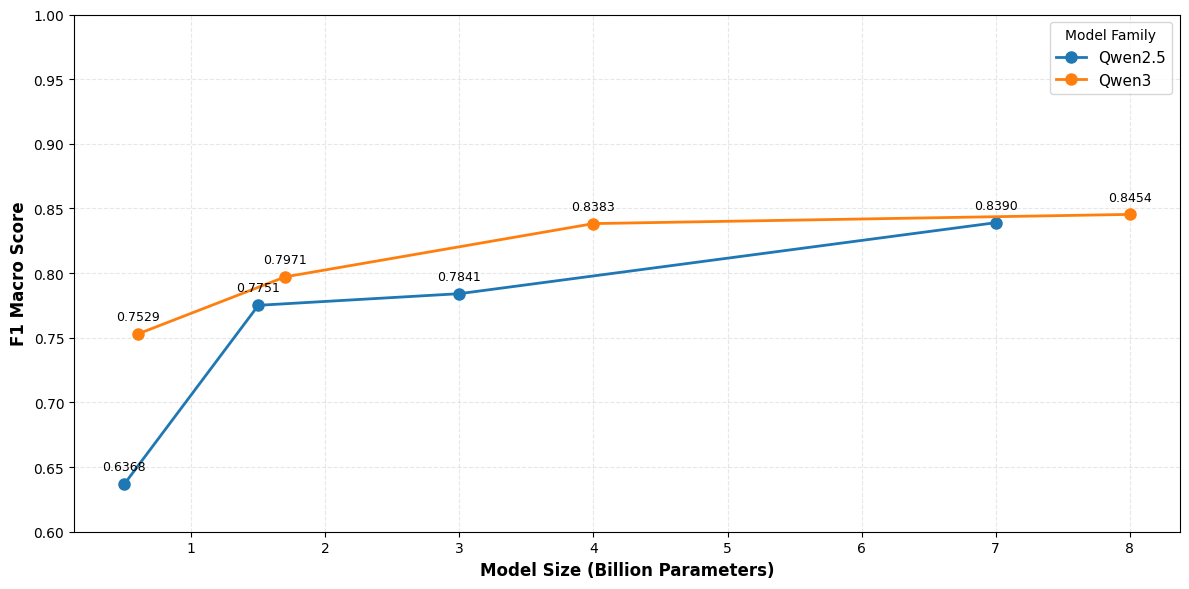

In [141]:
# Line chart: F1 Macro vs Model Size
import matplotlib.pyplot as plt

# Prepare data for line chart
line_df = plot_df.copy()

# Extract model family and size
line_df['Family'] = line_df['Model'].str.split('-').str[0]  # Qwen2.5 or Qwen3
line_df['Size'] = line_df['Model'].str.split('-').str[1]    # 0.5B, 1.5B, etc.

# Convert size to numeric (remove 'B' and convert to float)
line_df['Size_Numeric'] = line_df['Size'].str.replace('B', '').astype(float)

# Sort by size
line_df = line_df.sort_values('Size_Numeric')

# Create line chart
fig, ax = plt.subplots(figsize=(12, 6))

# Plot separate lines for each model family
for family in line_df['Family'].unique():
    family_data = line_df[line_df['Family'] == family]
    ax.plot(family_data['Size_Numeric'], family_data['F1 Macro'], 
            marker='o', linewidth=2, markersize=8, label=family)
    
    # Add value labels
    for x, y, model in zip(family_data['Size_Numeric'], family_data['F1 Macro'], family_data['Model']):
        ax.annotate(f'{y:.4f}', (x, y), textcoords="offset points", 
                   xytext=(0,10), ha='center', fontsize=9)

ax.set_xlabel('Model Size (Billion Parameters)', fontsize=12, fontweight='bold')
ax.set_ylabel('F1 Macro Score', fontsize=12, fontweight='bold')
# ax.set_title('F1 Macro Performance vs Model Size', fontsize=14, fontweight='bold')
ax.legend(title='Model Family', fontsize=11)
ax.grid(True, alpha=0.3, linestyle='--')
ax.set_ylim(bottom=0.6, top=1.0)

plt.tight_layout()
plt.savefig('../results/f1_vs_model_size.pdf', dpi=300, bbox_inches='tight')
print("\n✓ Line chart saved to ../results/f1_vs_model_size.png")
plt.show()


✓ Overall line chart saved to ../results/f1_vs_model_size_overall.png


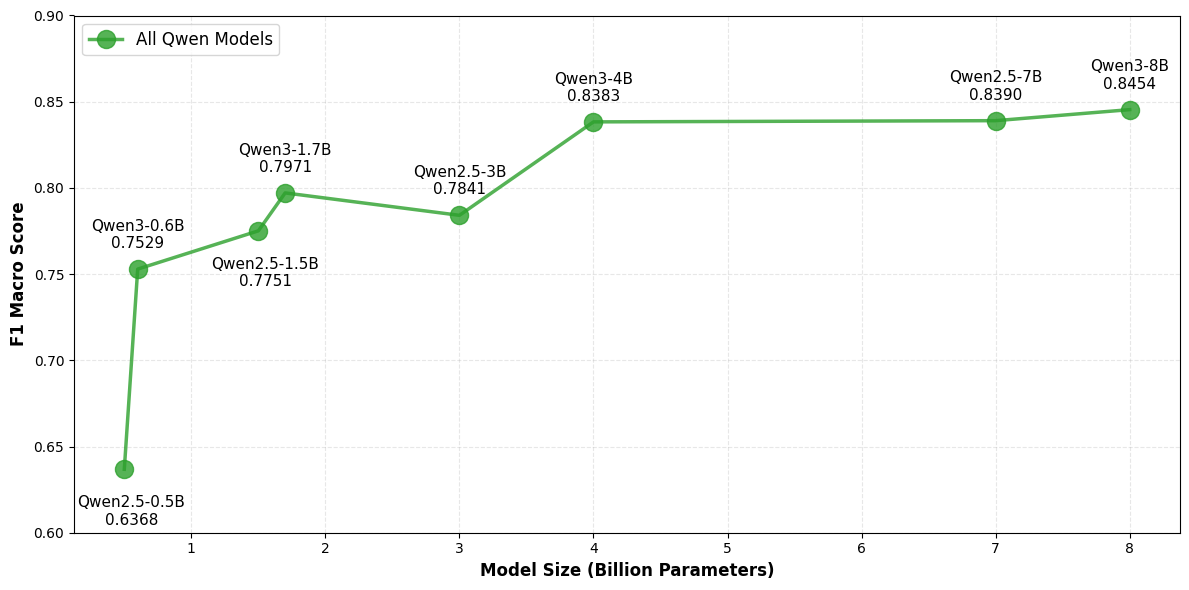

In [142]:
# Overall Qwen line chart
fig, ax = plt.subplots(figsize=(12, 6))

# Plot all Qwen models in one line
ax.plot(line_df['Size_Numeric'], line_df['F1 Macro'], 
        marker='o', linewidth=2.5, markersize=13, label='All Qwen Models', 
        color='#2ca02c', alpha=0.8)

# Add value labels
for x, y, model in zip(line_df['Size_Numeric'], line_df['F1 Macro'], line_df['Model']):
    if model == 'Qwen2.5-0.5B' or model == 'Qwen2.5-1.5B':
        ax.annotate(f'{model}\n{y:.4f}', (x, y), textcoords="offset points", 
                       xytext=(5,-40), ha='center', fontsize=11)
    else:    
        ax.annotate(f'{model}\n{y:.4f}', (x, y), textcoords="offset points", 
                   xytext=(0,15), ha='center', fontsize=11)

ax.set_xlabel('Model Size (Billion Parameters)', fontsize=12, fontweight='bold')
ax.set_ylabel('F1 Macro Score', fontsize=12, fontweight='bold')
# ax.set_title('Overall Qwen Performance: F1 Macro vs Model Size', fontsize=14, fontweight='bold')
ax.legend(fontsize=12, loc='upper left')
ax.grid(True, alpha=0.3, linestyle='--')
ax.set_ylim(bottom=0.6, top=0.9)

plt.tight_layout()
plt.savefig('../results/f1_vs_model_size_overall.pdf', dpi=300, bbox_inches='tight')
print("\n✓ Overall line chart saved to ../results/f1_vs_model_size_overall.png")
plt.show()


✓ Combined line chart saved to ../results/f1_vs_model_size_combined.png


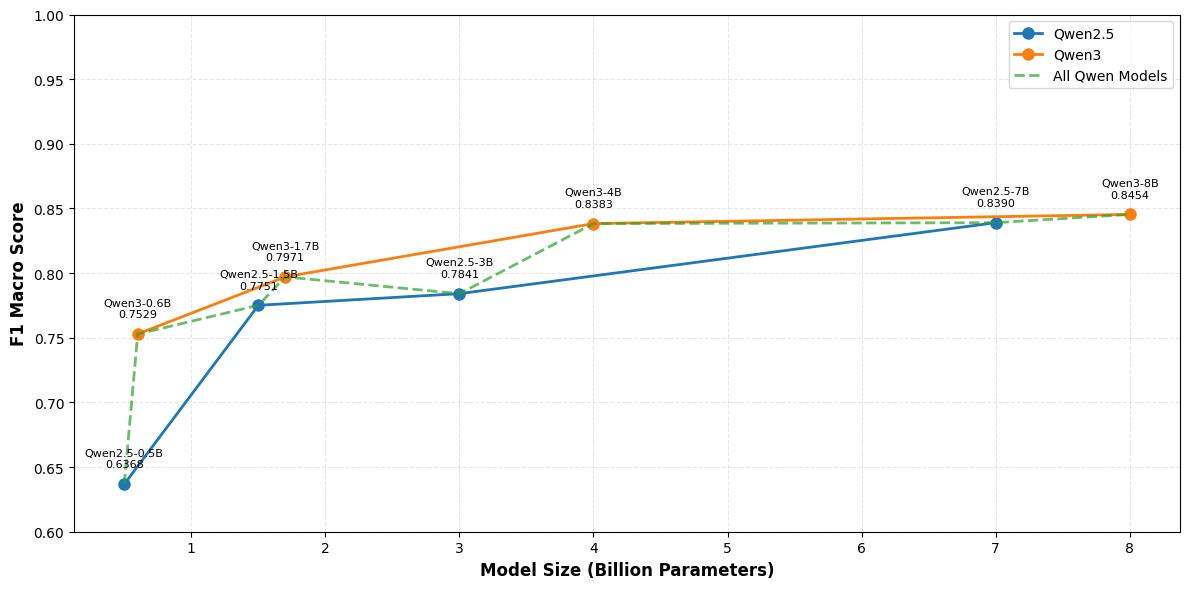

In [143]:
# Combined chart: family lines + overall line
import matplotlib.pyplot as plt

# Rebuild line_df if the previous cell has not run yet
if 'line_df' not in globals():
    plot_df = results_df.copy()
    for col in ['Accuracy', 'F1 Macro', 'F1 Weighted', 'Precision', 'Recall', 'AUC']:
        plot_df[col] = plot_df[col].astype(float)

    line_df = plot_df.copy()
    line_df['Family'] = line_df['Model'].str.split('-').str[0]
    line_df['Size'] = line_df['Model'].str.split('-').str[1]
    line_df['Size_Numeric'] = line_df['Size'].str.replace('B', '').astype(float)
    line_df = line_df.sort_values('Size_Numeric')

fig, ax = plt.subplots(figsize=(12, 6))

# Plot family lines
family_colors = {
    'Qwen2.5': '#1f77b4',
    'Qwen3': '#ff7f0e'
}

for family in line_df['Family'].unique():
    family_data = line_df[line_df['Family'] == family]
    ax.plot(
        family_data['Size_Numeric'],
        family_data['F1 Macro'],
        marker='o',
        linewidth=2,
        markersize=8,
        label=family,
        color=family_colors.get(family)
    )

# Plot overall line (no markers to reduce clutter)
ax.plot(
    line_df['Size_Numeric'],
    line_df['F1 Macro'],
    linestyle='--',
    linewidth=2,
    color='#2ca02c',
    alpha=0.7,
    label='All Qwen Models'
)

# Add model labels from the overall line
for x, y, model in zip(line_df['Size_Numeric'], line_df['F1 Macro'], line_df['Model']):
    ax.annotate(
        f'{model}\n{y:.4f}',
        (x, y),
        textcoords='offset points',
        xytext=(0, 12),
        ha='center',
        fontsize=8
    )

ax.set_xlabel('Model Size (Billion Parameters)', fontsize=12, fontweight='bold')
ax.set_ylabel('F1 Macro Score', fontsize=12, fontweight='bold')
ax.grid(True, alpha=0.3, linestyle='--')
ax.set_ylim(bottom=0.6, top=1.0)
ax.legend(fontsize=10)

plt.tight_layout()
plt.savefig('../results/f1_vs_model_size_combined.pdf', dpi=300, bbox_inches='tight')
plt.savefig('../results/f1_vs_model_size_combined.png', dpi=300, bbox_inches='tight')
print("\n✓ Combined line chart saved to ../results/f1_vs_model_size_combined.png")
plt.show()

In [144]:
# Per-class performance analysis
print("\n" + "="*100)
print("PER-CLASS PERFORMANCE ANALYSIS")
print("="*100)

for pred_file in prediction_files:
    model_name = pred_file.parent.name
    
    try:
        df = pd.read_csv(pred_file)
        
        print(f"\n{model_name}:")
        print("-" * 80)
        
        for label in ['no', 'intrinsic', 'extrinsic']:
            # Filter for this class
            mask = df['true_label'] == label
            correct = df[mask]['is_correct'].sum()
            total = mask.sum()
            accuracy = correct / total if total > 0 else 0
            
            print(f"  {label:12s}: {correct:3d}/{total:3d} correct = {accuracy:.4f} accuracy")
            
    except Exception as e:
        print(f"  Error: {e}")


PER-CLASS PERFORMANCE ANALYSIS

Qwen_Qwen2.5_0.5B:
--------------------------------------------------------------------------------
  no          : 434/690 correct = 0.6290 accuracy
  intrinsic   : 403/672 correct = 0.5997 accuracy
  extrinsic   : 431/638 correct = 0.6755 accuracy

Qwen_Qwen2.5_1.5B:
--------------------------------------------------------------------------------
  no          : 552/690 correct = 0.8000 accuracy
  intrinsic   : 475/672 correct = 0.7068 accuracy
  extrinsic   : 523/638 correct = 0.8197 accuracy

Qwen_Qwen2.5_3B:
--------------------------------------------------------------------------------
  no          : 544/690 correct = 0.7884 accuracy
  intrinsic   : 506/672 correct = 0.7530 accuracy
  extrinsic   : 515/638 correct = 0.8072 accuracy

Qwen_Qwen2.5_7B:
--------------------------------------------------------------------------------
  no          : 619/690 correct = 0.8971 accuracy
  intrinsic   : 612/672 correct = 0.9107 accuracy
  extrinsic   : 58